# import libarires

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score ,confusion_matrix,classification_report,ConfusionMatrixDisplay ,
    average_precision_score ,roc_auc_score ,
    roc_curve, roc_auc_score, precision_recall_curve,
)
from sklearn.calibration import calibration_curve
from feature_engine.imputation import AddMissingIndicator, MeanMedianImputer
from feature_engine.discretisation import EqualFrequencyDiscretiser
from feature_engine.encoding import WoEEncoder

# import dataset

In [2]:
df = pd.read_csv("../01_data/credit_risk_clean.csv")
df.head()

,age,annual_income,home_ownership,employment_years,loan_purpose,credit_grade,loan_amount,interest_rate,default_flag,loan_income_ratio,prior_default_flag,credit_history_years
0,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
1,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
2,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
3,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
4,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2


In [3]:
numeric_columns = [
    "age", "annual_income", "employment_years", "loan_amount",
    "interest_rate", "loan_income_ratio", "credit_history_years",
]

categorical_columns = [
    "home_ownership", "loan_purpose", "credit_grade", "prior_default_flag",
]

all_features = numeric_columns + categorical_columns

In [4]:
X = df[all_features]
y = df['default_flag']

# train test split

In [5]:
X_train, X_test , y_train ,y_test = train_test_split(
    X,y,         # feature and target
    test_size = 0.2,
    stratify= y,
    random_state = 42
)

In [6]:
print("Shape of Training data is :", X_train.shape,y_train.shape)
print("Shape of Testing data  is :", X_test.shape,y_test.shape)

Shape of Training data is : (25927, 11) (25927,)
Shape of Testing data  is : (6482, 11) (6482,)


In [7]:
# Q: How many defautls and non defaults in training and testing data 
print("Training data \n", y_train.value_counts(normalize=True).to_dict())
print("Testing data \n" ,y_test.value_counts(normalize=True).to_dict())

Training data 
 {0: 0.7813090600532263, 1: 0.21869093994677363}
Testing data 
 {0: 0.781240357914224, 1: 0.218759642085776}


# misssing values

In [8]:
X_train.isna().sum()

age                        0
annual_income              0
employment_years         710
loan_amount                0
interest_rate           2463
loan_income_ratio          0
credit_history_years       0
home_ownership             0
loan_purpose               0
credit_grade               0
prior_default_flag         0
dtype: int64

In [9]:
X_test.isna().sum()

age                       0
annual_income             0
employment_years        177
loan_amount               0
interest_rate           631
loan_income_ratio         0
credit_history_years      0
home_ownership            0
loan_purpose              0
credit_grade              0
prior_default_flag        0
dtype: int64

In [10]:
missing_cols = X_train[numeric_columns].columns[X_train[numeric_columns].isna().any()].tolist()
missing_cols

['employment_years', 'interest_rate']

In [11]:
missing_indicator = AddMissingIndicator(variables=missing_cols)
median_imputer = MeanMedianImputer(imputation_method='median',variables=missing_cols)


In [12]:
# Step 1: Add missing indicator columns
# - fit_transform on Train to learn and transform
# - transform on Test using the parameters learned from Train
X_train = missing_indicator.fit_transform(X_train)
X_test = missing_indicator.transform(X_test)

# Step 2: Impute missing values with medians
# - fit_transform on Train to calculate medians and fill missing values
# - transform on Test to fill missing values using X_train medians
X_train = median_imputer.fit_transform(X_train)
X_test = median_imputer.transform(X_test)

In [13]:
X_train.isna().sum()

age                     0
annual_income           0
employment_years        0
loan_amount             0
interest_rate           0
loan_income_ratio       0
credit_history_years    0
home_ownership          0
loan_purpose            0
credit_grade            0
prior_default_flag      0
employment_years_na     0
interest_rate_na        0
dtype: int64

In [14]:
X_test.isna().sum()

age                     0
annual_income           0
employment_years        0
loan_amount             0
interest_rate           0
loan_income_ratio       0
credit_history_years    0
home_ownership          0
loan_purpose            0
credit_grade            0
prior_default_flag      0
employment_years_na     0
interest_rate_na        0
dtype: int64

In [15]:
indicator_cols = [c for c in X_train.columns if c.endswith('_na')]
indicator_cols

['employment_years_na', 'interest_rate_na']

In [16]:
X_train

,age,annual_income,employment_years,loan_amount,interest_rate,loan_income_ratio,credit_history_years,home_ownership,loan_purpose,credit_grade,prior_default_flag,employment_years_na,interest_rate_na
31112,37,85000,19.0,10000,9.99,0.12,16,MORTGAGE,HOMEIMPROVEMENT,B,N,0,0
5364,25,50000,7.0,8500,15.70,0.17,4,RENT,EDUCATION,E,N,0,0
13349,26,90000,1.0,20000,10.99,0.22,3,MORTGAGE,PERSONAL,B,N,0,1
31695,41,88712,2.0,16000,10.95,0.18,15,RENT,VENTURE,B,N,0,0
24075,35,39000,2.0,10000,13.16,0.26,6,RENT,MEDICAL,C,N,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32122,38,110000,5.0,16000,11.99,0.15,13,MORTGAGE,MEDICAL,B,N,0,0
18667,30,14800,5.0,1200,8.00,0.08,9,RENT,DEBTCONSOLIDATION,A,N,0,0
30477,39,60000,3.0,8000,9.88,0.13,14,RENT,PERSONAL,B,N,0,0
17957,30,180000,2.0,12500,6.03,0.07,6,MORTGAGE,DEBTCONSOLIDATION,A,N,0,0


# quantile bining
Convert Numerical Variable ---> Categorical         
splitting data into equal-sized groups(categories)               
$I_k = \left[ Q\left(\frac{k-1}{q}\right), Q\left(\frac{k}{q}\right) \right)$


In [17]:
quantile_binner = EqualFrequencyDiscretiser(
    q=10, 
    variables=numeric_columns, 
    return_object=True
)
X_train = quantile_binner.fit_transform(X_train)
X_test = quantile_binner.transform(X_test)

In [18]:
X_train

,age,annual_income,employment_years,loan_amount,interest_rate,loan_income_ratio,credit_history_years,home_ownership,loan_purpose,credit_grade,prior_default_flag,employment_years_na,interest_rate_na
31112,9,7,8,5,3,3,6,MORTGAGE,HOMEIMPROVEMENT,B,N,0,0
5364,3,4,6,5,9,5,1,RENT,EDUCATION,E,N,0,0
13349,4,8,0,9,4,7,0,MORTGAGE,PERSONAL,B,N,0,1
31695,9,8,1,8,4,5,6,RENT,VENTURE,B,N,0,0
24075,8,2,1,5,7,8,3,RENT,MEDICAL,C,N,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32122,9,8,4,8,6,4,6,MORTGAGE,MEDICAL,B,N,0,0
18667,7,0,4,0,2,1,4,RENT,DEBTCONSOLIDATION,A,N,0,0
30477,9,5,2,4,3,4,6,RENT,PERSONAL,B,N,0,0
17957,7,9,1,7,0,1,3,MORTGAGE,DEBTCONSOLIDATION,A,N,0,0


In [19]:
# Define full encoding column list including categoricals and missing indicators
all_encode_columns = numeric_columns + categorical_columns
all_encode_columns

['age',
 'annual_income',
 'employment_years',
 'loan_amount',
 'interest_rate',
 'loan_income_ratio',
 'credit_history_years',
 'home_ownership',
 'loan_purpose',
 'credit_grade',
 'prior_default_flag']

In [20]:
all_encode_columns

['age',
 'annual_income',
 'employment_years',
 'loan_amount',
 'interest_rate',
 'loan_income_ratio',
 'credit_history_years',
 'home_ownership',
 'loan_purpose',
 'credit_grade',
 'prior_default_flag']

In [21]:
X_train

,age,annual_income,employment_years,loan_amount,interest_rate,loan_income_ratio,credit_history_years,home_ownership,loan_purpose,credit_grade,prior_default_flag,employment_years_na,interest_rate_na
31112,9,7,8,5,3,3,6,MORTGAGE,HOMEIMPROVEMENT,B,N,0,0
5364,3,4,6,5,9,5,1,RENT,EDUCATION,E,N,0,0
13349,4,8,0,9,4,7,0,MORTGAGE,PERSONAL,B,N,0,1
31695,9,8,1,8,4,5,6,RENT,VENTURE,B,N,0,0
24075,8,2,1,5,7,8,3,RENT,MEDICAL,C,N,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32122,9,8,4,8,6,4,6,MORTGAGE,MEDICAL,B,N,0,0
18667,7,0,4,0,2,1,4,RENT,DEBTCONSOLIDATION,A,N,0,0
30477,9,5,2,4,3,4,6,RENT,PERSONAL,B,N,0,0
17957,7,9,1,7,0,1,3,MORTGAGE,DEBTCONSOLIDATION,A,N,0,0


In [22]:
# Cast all features to category dtype for feature-engine WoE compliance
for col in all_encode_columns:
    X_train[col] = X_train[col].astype('category')
    X_test[col] = X_test[col].astype('category')

In [23]:
X_train

,age,annual_income,employment_years,loan_amount,interest_rate,loan_income_ratio,credit_history_years,home_ownership,loan_purpose,credit_grade,prior_default_flag,employment_years_na,interest_rate_na
31112,9,7,8,5,3,3,6,MORTGAGE,HOMEIMPROVEMENT,B,N,0,0
5364,3,4,6,5,9,5,1,RENT,EDUCATION,E,N,0,0
13349,4,8,0,9,4,7,0,MORTGAGE,PERSONAL,B,N,0,1
31695,9,8,1,8,4,5,6,RENT,VENTURE,B,N,0,0
24075,8,2,1,5,7,8,3,RENT,MEDICAL,C,N,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32122,9,8,4,8,6,4,6,MORTGAGE,MEDICAL,B,N,0,0
18667,7,0,4,0,2,1,4,RENT,DEBTCONSOLIDATION,A,N,0,0
30477,9,5,2,4,3,4,6,RENT,PERSONAL,B,N,0,0
17957,7,9,1,7,0,1,3,MORTGAGE,DEBTCONSOLIDATION,A,N,0,0


In [24]:
X_train.drop(columns = indicator_cols,inplace = True)
X_test.drop(columns = indicator_cols,inplace = True)

# Weight of Evidence (WoE)
Weight of Evidence (WoE) transforms categorical values into continuous numeric values representing the natural log-odds of the target outcome.          
$\text{WoE}_i = \ln \left( \frac{\% \text{ Good}_i}{\% \text{ Bad}_i} \right) = \ln \left( \frac{\text{Good}_i / \text{Good}_{\text{total}}}{\text{Bad}_i / \text{Bad}_{\text{total}}} \right)$             
Log of a number > 1 means positive value. If less than 1, it means negative value.


In [25]:
woe_encoder = WoEEncoder(variables=all_encode_columns)
X_train_woe = woe_encoder.fit_transform(X_train, y_train)
X_test_woe = woe_encoder.transform(X_test)

In [26]:
X_train_woe

,age,annual_income,employment_years,loan_amount,interest_rate,loan_income_ratio,credit_history_years,home_ownership,loan_purpose,credit_grade,prior_default_flag
31112,-0.050646,-0.612238,-0.380067,-0.132917,-0.401392,-0.698532,-0.027408,-0.668658,0.254669,-0.352006,-0.203381
5364,0.021899,-0.121454,-0.243211,-0.132917,1.668766,-0.232852,0.038704,0.504774,-0.297176,1.911326,-0.203381
13349,-0.086282,-1.002990,0.303641,0.604121,-0.152715,-0.144767,0.064631,-0.668658,-0.133226,-0.352006,-0.203381
31695,-0.050646,-1.002990,0.217038,0.356750,-0.152715,-0.232852,-0.027408,0.504774,-0.436693,-0.352006,-0.203381
24075,-0.048297,0.090155,0.217038,-0.132917,-0.054267,0.665435,-0.109207,0.504774,0.251817,-0.092992,-0.203381
...,...,...,...,...,...,...,...,...,...,...,...
32122,-0.050646,-1.002990,-0.187253,0.356750,-0.172345,-0.618892,-0.027408,-0.668658,0.251817,-0.352006,-0.203381
18667,-0.127555,1.124388,-0.187253,-0.039106,-0.614725,-0.690819,-0.073924,0.504774,0.354674,-0.921311,-0.203381
30477,-0.050646,-0.236043,-0.084812,-0.300796,-0.401392,-0.618892,-0.027408,0.504774,-0.133226,-0.352006,-0.203381
17957,-0.127555,-1.014332,0.217038,0.203118,-1.171279,-0.690819,-0.109207,-0.668658,0.354674,-0.921311,-0.203381


In [27]:
X_test_woe

,age,annual_income,employment_years,loan_amount,interest_rate,loan_income_ratio,credit_history_years,home_ownership,loan_purpose,credit_grade,prior_default_flag
16587,0.238978,0.055234,-0.084812,-0.156212,-0.355929,-0.698532,0.038704,0.504774,-0.133226,-0.092992,0.739693
26852,-0.127555,-1.002990,-0.380067,0.604121,-0.054267,0.665435,-0.043488,-0.668658,0.354674,-0.092992,-0.203381
19721,-0.127555,0.090155,-0.187253,-0.102195,-0.401392,0.665435,-0.043488,0.504774,0.251817,-0.352006,-0.203381
24055,-0.127555,0.055234,0.112449,-0.132917,-0.152715,-0.144767,-0.090069,0.504774,-0.297176,-0.352006,-0.203381
24943,-0.048297,0.893621,0.112449,-0.102195,-0.401392,2.174970,-0.090069,0.504774,0.251817,-0.352006,-0.203381
...,...,...,...,...,...,...,...,...,...,...,...
7637,-0.007983,1.124388,0.303641,-0.300796,-1.171279,0.665435,0.038704,0.504774,0.251817,-0.921311,-0.203381
10310,-0.007983,-0.236043,-0.243211,0.356750,-0.355929,0.665435,0.038704,0.504774,0.354674,-0.352006,-0.203381
2328,-0.016770,0.893621,-0.178413,-0.039106,-1.171279,-0.690819,0.038704,-1.255080,-0.297176,-0.921311,-0.203381
28150,-0.048331,-0.121454,0.112449,-0.300796,-0.152715,-0.618892,-0.073924,0.504774,-0.133226,-0.352006,-0.203381


# information value(IV)
Information Value (IV) quantifies the overall predictive power of a categorical feature to separate binary outcomes (such as "Good" vs. "Bad" or "Default" vs. "Non-default"). While Weight of Evidence (WoE) measures predictive power at the individual bin level, IV aggregates WoE across all bins into a single metric for the entire feature.
$$IV = \sum_{i=1}^{k} \left( \% \text{Goods}_i - \% \text{Bads}_i \right) \times \text{WoE}_i$$

Where:

* $\% \text{Goods}_i = \frac{\text{Goods in bin } i}{\text{Total Goods}}$
* $\% \text{Bads}_i = \frac{\text{Bads in bin } i}{\text{Total Bads}}$
* $\text{WoE}_i = \ln\left(\frac{\% \text{Goods}_i}{\% \text{Bads}_i}\right)$

In [4]:
def calculate_iv(binned_col, target):
    df_iv = pd.DataFrame({'bin': binned_col, 'target': target})
    grouped = df_iv.groupby('bin', observed=True)['target'].agg(['count', 'sum'])
    grouped.columns = ['total', 'bad']
    grouped['good'] = grouped['total'] - grouped['bad']
    grouped['pct_good'] = (grouped['good'] / grouped['good'].sum()).replace(0, 0.0001)
    grouped['pct_bad'] = (grouped['bad'] / grouped['bad'].sum()).replace(0, 0.0001)
    grouped['woe'] = np.log(grouped['pct_good'] / grouped['pct_bad'])
    grouped['iv'] = (grouped['pct_good'] - grouped['pct_bad']) * grouped['woe']
    return grouped['iv'].sum()

iv_results = {col: calculate_iv(X_train[col], y_train) for col in all_encode_columns}
iv_table = pd.DataFrame(
    sorted(iv_results.items(), key=lambda x: x[1], reverse=True),
    columns=['Variable', 'IV']
)
print("\n=== Full IV Ranking ===")
print(iv_table)


=== Full IV Ranking ===
                Variable        IV
0           credit_grade  0.882084
1      loan_income_ratio  0.877676
2          interest_rate  0.652975
3          annual_income  0.467656
4         home_ownership  0.381460
5     prior_default_flag  0.148590
6           loan_purpose  0.090643
7            loan_amount  0.087451
8       employment_years  0.057001
9                    age  0.012516
10  credit_history_years  0.004444


# visulaise way

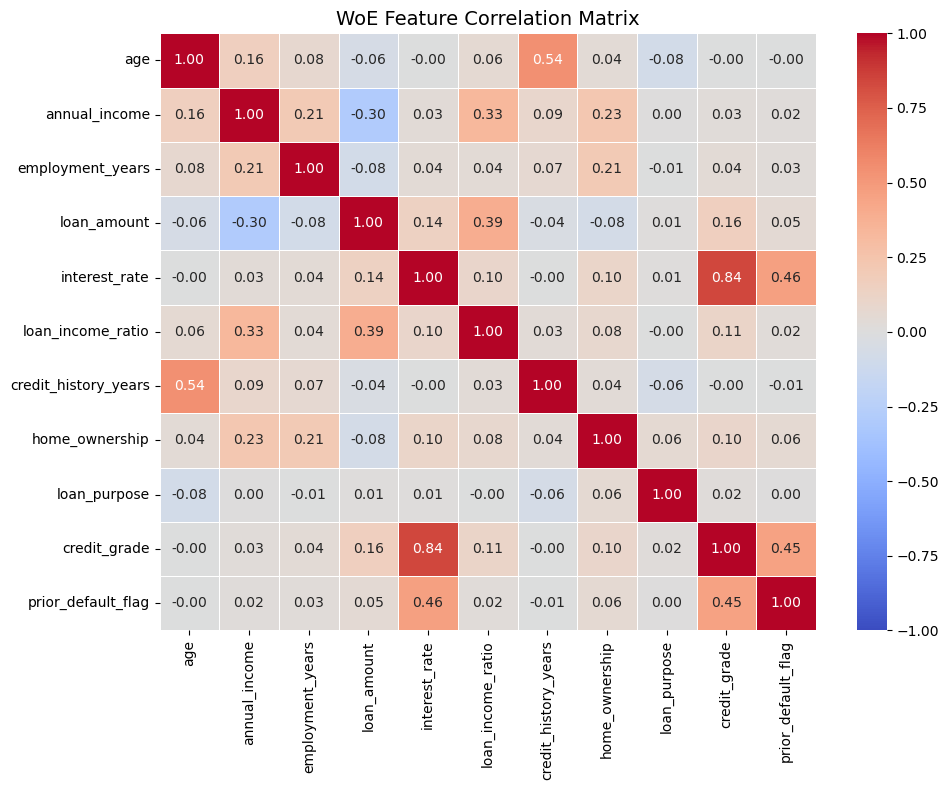

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
corr = X_train_woe.corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title("WoE Feature Correlation Matrix", fontsize=14)
plt.tight_layout()
plt.show()

strong multicollinary between interset rate and credit grade 0.84

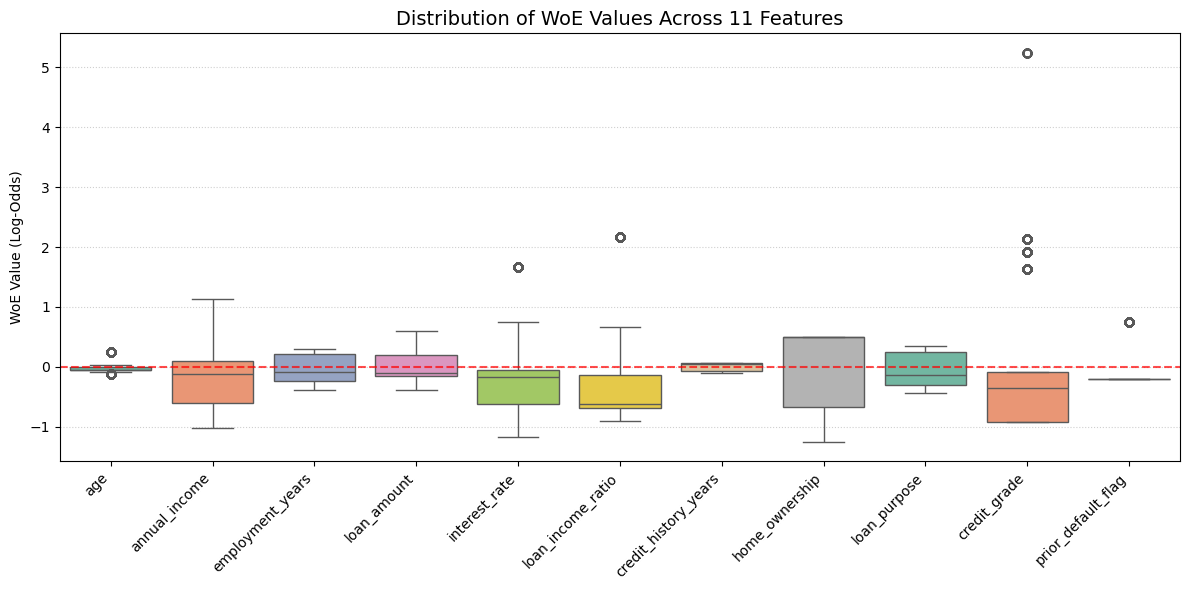

In [30]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=X_train_woe, palette="Set2")
plt.xticks(rotation=45, ha="right")
plt.ylabel("WoE Value (Log-Odds)")
plt.title("Distribution of WoE Values Across 11 Features", fontsize=14)
plt.axhline(0, color="red", linestyle="--", alpha=0.7)  # Neutral log-odds reference
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

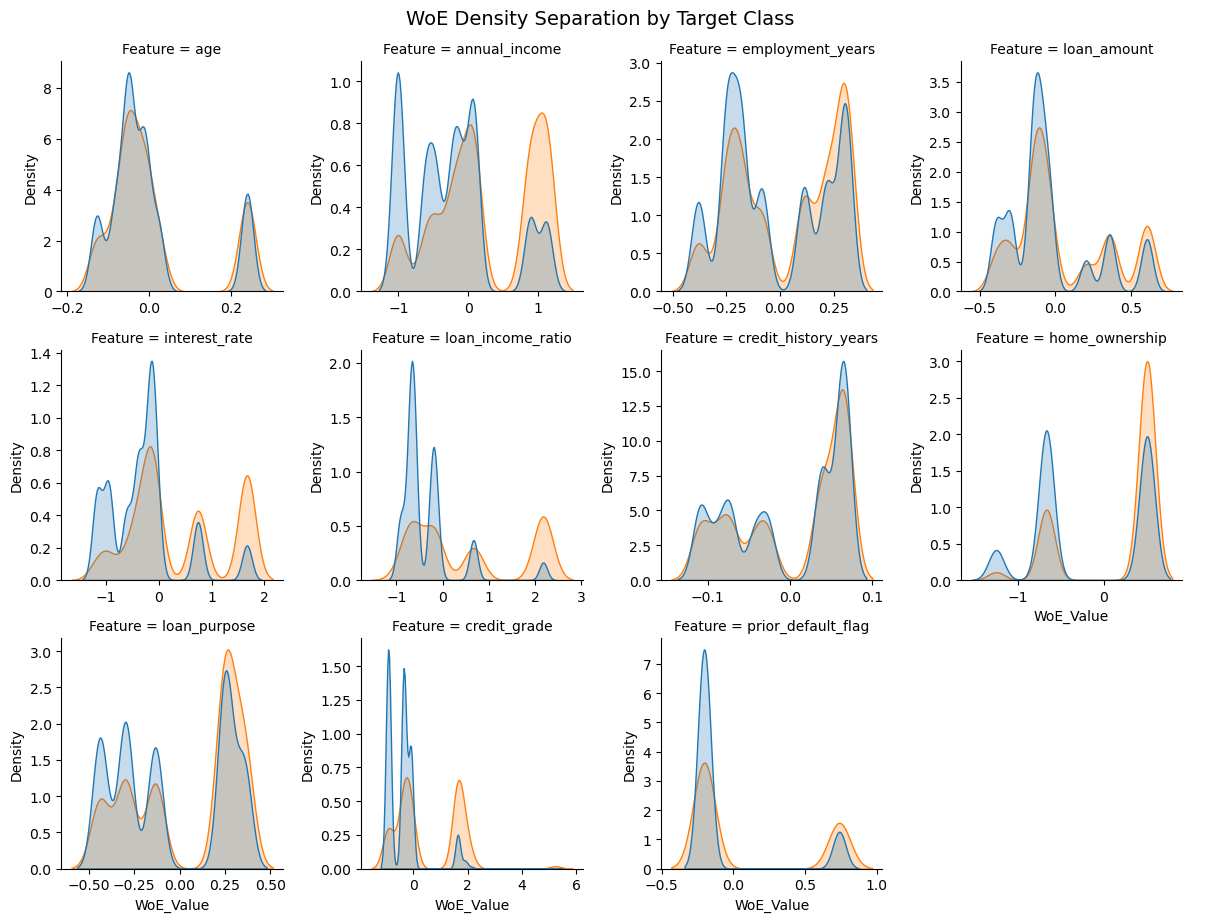

In [31]:
# Melt dataset for faceted plotting if y_train is available
df_plot = X_train_woe.copy()
df_plot["Target"] = y_train

df_melted = df_plot.melt(
    id_vars="Target", var_name="Feature", value_name="WoE_Value"
)

g = sns.FacetGrid(
    df_melted, col="Feature", col_wrap=4, sharex=False, sharey=False, height=3
)
g.map_dataframe(
    sns.kdeplot, x="WoE_Value", hue="Target", common_norm=False, fill=True
)
g.add_legend()
g.fig.suptitle("WoE Density Separation by Target Class", y=1.02, fontsize=14)
plt.show()

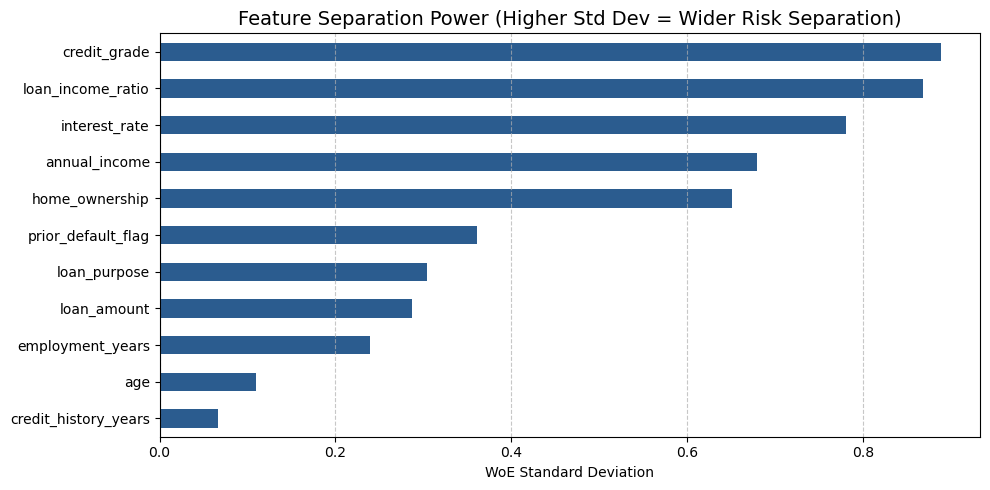

In [32]:
# Calculate standard deviation of WoE per feature
woe_variance = X_train_woe.std().sort_values(ascending=True)

plt.figure(figsize=(10, 5))
woe_variance.plot(kind="barh", color="#2b5c8f")
plt.xlabel("WoE Standard Deviation")
plt.title(
    "Feature Separation Power (Higher Std Dev = Wider Risk Separation)",
    fontsize=14,
)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

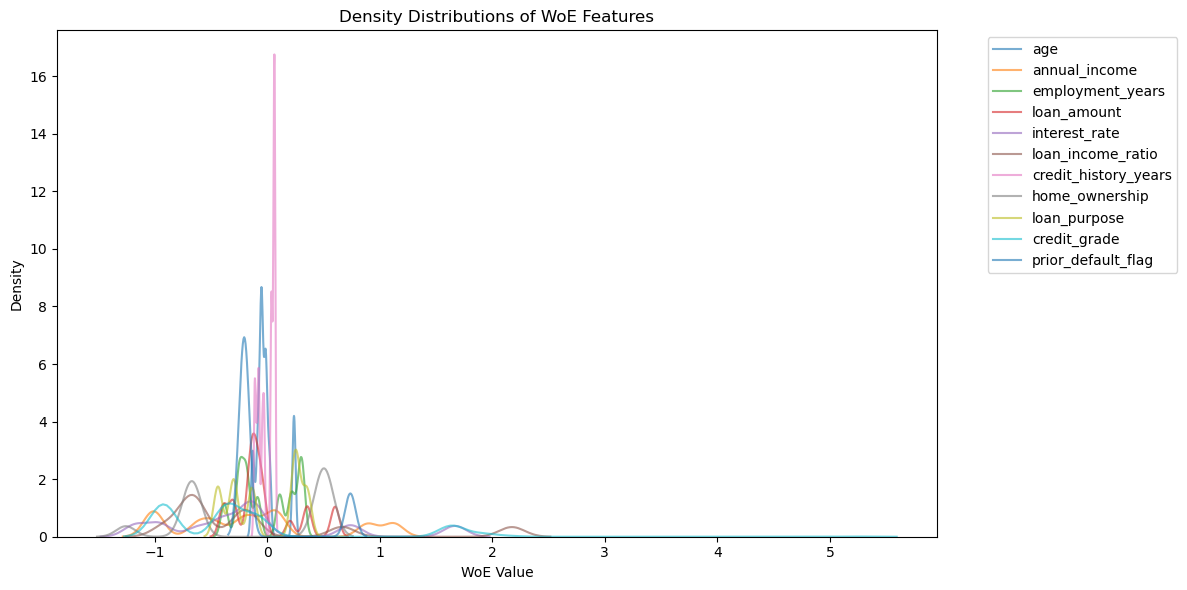

In [33]:
plt.figure(figsize=(12, 6))
for col in X_train_woe.columns:
    sns.kdeplot(X_train_woe[col], label=col, alpha=0.6)

plt.xlabel("WoE Value")
plt.ylabel("Density")
plt.title("Density Distributions of WoE Features")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

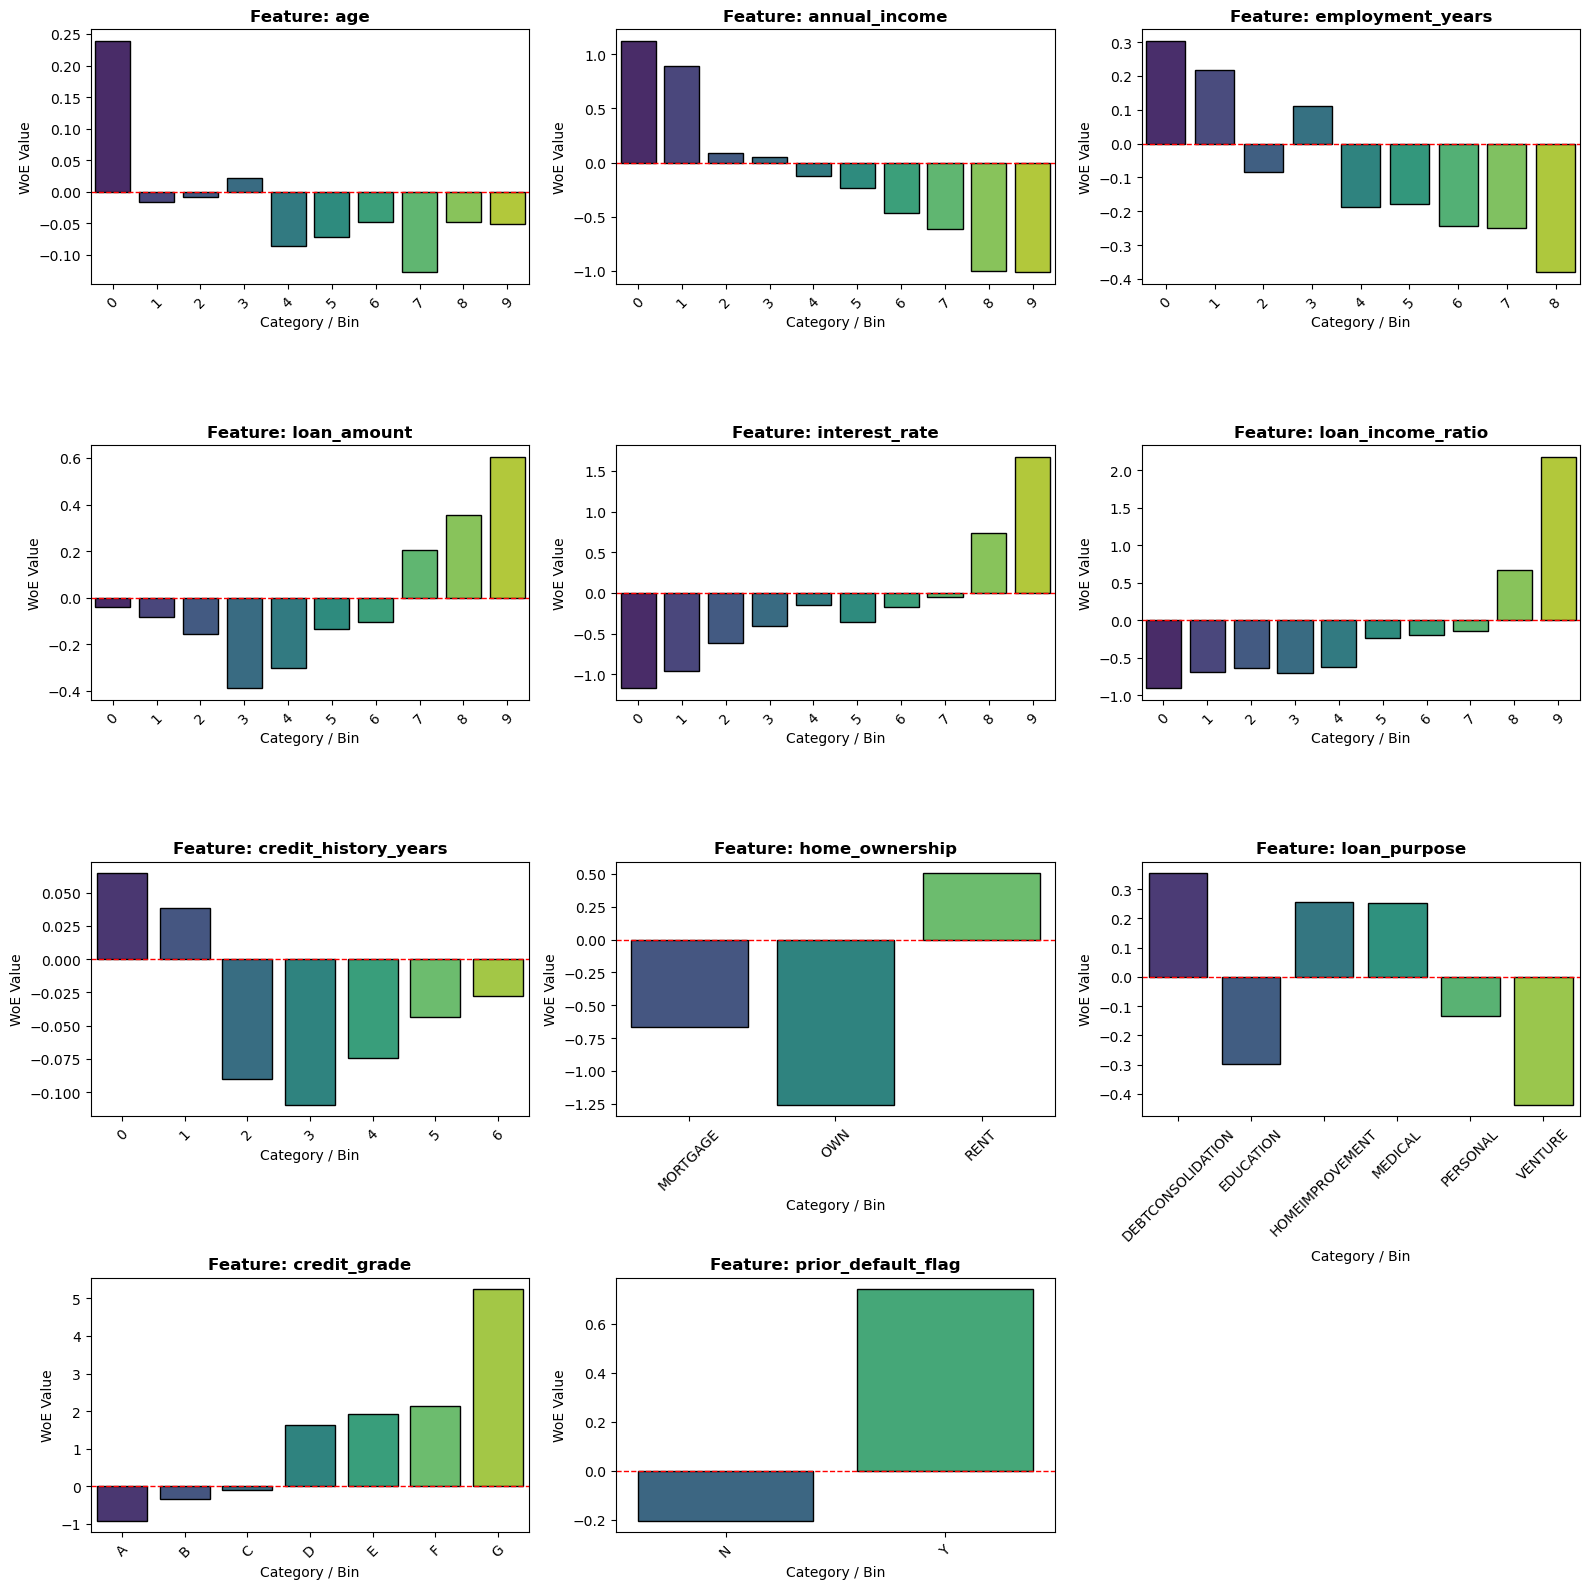

In [34]:
import math
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

feature_cols = X_train_woe.columns

num_features = len(feature_cols)
ncols = 3
nrows = math.ceil(num_features / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(16, nrows * 4))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    df_map = (
        pd.DataFrame({"Category": X_train[col], "WoE": X_train_woe[col]})
        .drop_duplicates()
        .sort_values("WoE")
    )

    # Plot bar graph with fixed hue parameters
    sns.barplot(
        data=df_map,
        x="Category",
        y="WoE",
        hue="Category",  # Assign x variable to hue
        legend=False,  # Disable redundant legend popup
        ax=axes[i],
        palette="viridis",
        edgecolor="black",
    )

    axes[i].set_title(f"Feature: {col}", fontsize=12, fontweight="bold")
    axes[i].set_xlabel("Category / Bin")
    axes[i].set_ylabel("WoE Value")
    axes[i].axhline(0, color="red", linestyle="--", linewidth=1)
    axes[i].tick_params(axis="x", rotation=45)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# logistic regression

In [35]:
logistic_regression_model = LogisticRegression()
logistic_regression_model.fit(X_train_woe,y_train)

LogisticRegression()

In [57]:
# probability of default
y_prob = logistic_regression_model.predict_proba(X_test_woe)[:, 1]      
y_prob

array([0.12976749, 0.16081937, 0.40964477, ..., 0.01656296, 0.09266674,
       0.1354422 ])

In [59]:
# predication hard class at 0.5
y_pred = logistic_regression_model.predict(X_test_woe)
y_pred

array([0, 0, 0, ..., 0, 0, 0], dtype=int64)

In [36]:
print(logistic_regression_model.intercept_)
print(logistic_regression_model.coef_)

[-1.35394487]
[[ 0.21491637  0.80946115  0.28266075  0.37557427  0.08365528  0.96265034
   0.17571019  0.92451808  1.43107385  1.14279571 -0.0497877 ]]


In [37]:
X_train_woe.columns

Index(['age', 'annual_income', 'employment_years', 'loan_amount',
       'interest_rate', 'loan_income_ratio', 'credit_history_years',
       'home_ownership', 'loan_purpose', 'credit_grade', 'prior_default_flag'],
      dtype='object')

In [38]:
pd.DataFrame(index=X_train_woe.columns,data=np.round(logistic_regression_model.coef_.ravel(),2))

,0
age,0.21
annual_income,0.81
employment_years,0.28
loan_amount,0.38
interest_rate,0.08
loan_income_ratio,0.96
credit_history_years,0.18
home_ownership,0.92
loan_purpose,1.43
credit_grade,1.14


# Evalution metrices

## Accuracy score

In [46]:
print('Accuracy_score :',accuracy_score(y_test,y_pred))

Accuracy_score : 0.8711817340327059


## confusion matrix 

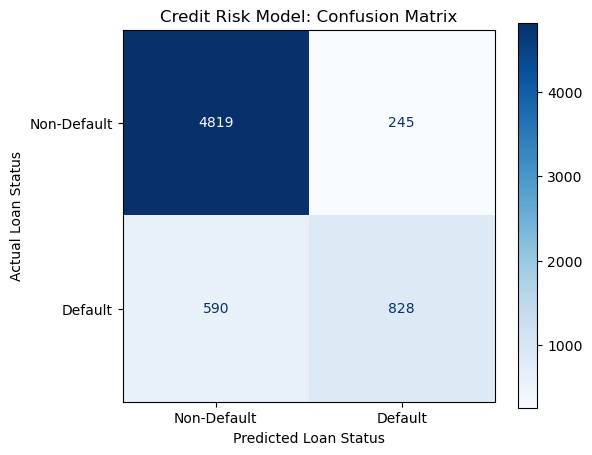

In [45]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Default", "Default"],
)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", ax=ax, values_format="d")

ax.set_xlabel("Predicted Loan Status")
ax.set_ylabel("Actual Loan Status")
ax.set_title("Credit Risk Model: Confusion Matrix")
plt.show()

## classification report

In [47]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, target_names=["Non-Default", "Default"]))

              precision    recall  f1-score   support

 Non-Default       0.89      0.95      0.92      5064
     Default       0.77      0.58      0.66      1418

    accuracy                           0.87      6482
   macro avg       0.83      0.77      0.79      6482
weighted avg       0.86      0.87      0.86      6482



recall of default is 0.58           
Low recall means you approve many defaulters, the most costly error.

# AUC-ROC curve
The ROC curve plots TPR against FPR for every possible cut-off. AUC is the area under it.
Meaning: AUC is the probability that a randomly chosen defaulter gets a higher risk score than a randomly chosen non-defaulter. 0.5 = random, 1.0 = perfect. AUC = 0.78 means 78% of such pairs are ranked correctly.

how well the model ranks defaulters above non-defaulters. It doesn't depend on a threshold.

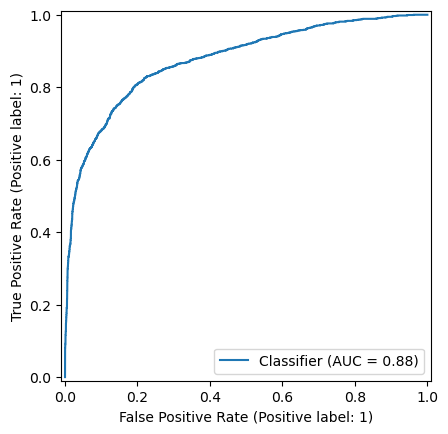

auc : 0.8761352571429845


In [62]:
from sklearn.metrics import roc_auc_score, roc_curve, RocCurveDisplay
auc = roc_auc_score(y_test, y_prob)
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.show()
print('auc :' , auc)

# Gini
$ Gini = 2 × AUC − 1 $

In [63]:
gini = 2 * auc - 1
print('gini :',gini)

gini : 0.7522705142859689


# KS statistic
The maximum vertical gap between the cumulative % of bads and cumulative % of goods when sorted by score.

In [78]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
best_cutoff = thresholds[np.argmax(tpr - fpr)]
print(best_cutoff)

0.2201392720726887


In [79]:
ks = np.max(tpr - fpr)
print(ks)

0.6116111515896943


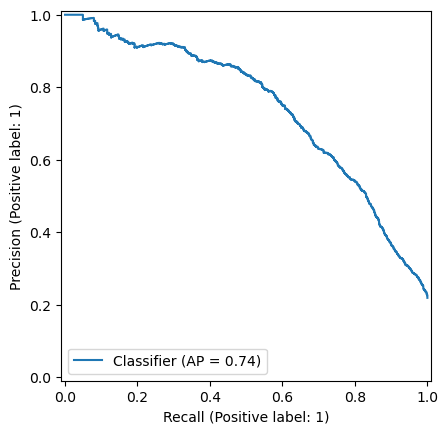

average_precision_score : 0.7436029206732877


In [81]:
from sklearn.metrics import average_precision_score, PrecisionRecallDisplay
average_precision_score(y_test, y_prob)
PrecisionRecallDisplay.from_predictions(y_test, y_prob); plt.show()
print('average_precision_score :',average_precision_score(y_test, y_prob))

# Calibration_curve

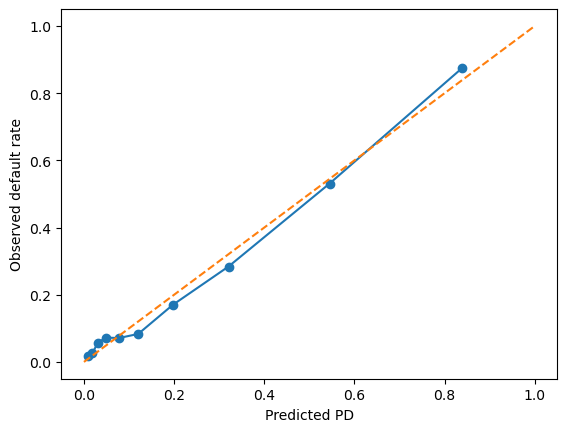

In [82]:
from sklearn.calibration import calibration_curve
frac_pos, mean_pred = calibration_curve(y_test, y_prob, n_bins=10, strategy="quantile")
plt.plot(mean_pred, frac_pos, marker="o"); plt.plot([0, 1], [0, 1], "--")
plt.xlabel("Predicted PD"); plt.ylabel("Observed default rate"); plt.show()

In [84]:
import numpy as np
import pandas as pd

def find_cost_optimal_threshold(y_true, y_proba, cost_fn=5, cost_fp=1, thresholds=None):
    """
    Finds the threshold that minimizes total expected cost.
    
    cost_fn : cost of a False Negative (approving a defaulter) — usually HIGH
    cost_fp : cost of a False Positive (rejecting a good applicant) — usually LOWER
    """
    if thresholds is None:
        thresholds = np.arange(0.05, 0.95, 0.01)
    
    results = []
    for t in thresholds:
        y_pred = (y_proba >= t).astype(int)
        
        fn = np.sum((y_true == 1) & (y_pred == 0))  # missed defaulters
        fp = np.sum((y_true == 0) & (y_pred == 1))  # wrongly rejected good applicants
        
        total_cost = fn * cost_fn + fp * cost_fp
        results.append({'threshold': t, 'FN': fn, 'FP': fp, 'total_cost': total_cost})
    
    results_df = pd.DataFrame(results)
    best_row = results_df.loc[results_df['total_cost'].idxmin()]
    
    return best_row['threshold'], results_df

# Usage — you decide the cost ratio based on domain reasoning
best_threshold, cost_curve = find_cost_optimal_threshold(
    y_test, y_prob, cost_fn=5, cost_fp=1
)
print(f"Cost-optimal threshold: {best_threshold:.3f}")

Cost-optimal threshold: 0.190


In [87]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve, RocCurveDisplay,
    precision_recall_curve, PrecisionRecallDisplay,
    ConfusionMatrixDisplay, confusion_matrix,
    fbeta_score, roc_auc_score
)


def find_threshold_and_plot(y_true, y_proba, beta=2, figsize=(15, 4)):
    """
    Plots ROC curve, PR curve, and Confusion Matrix (at optimal threshold)
    side by side using sklearn's built-in Display classes.
    Finds threshold two ways: Youden's J (ROC) and F-beta (PR).
    
    Parameters:
    -----------
    y_true : array-like, true binary labels
    y_proba : array-like, predicted probabilities
    beta : float, beta for F-beta score (2 = recall weighted higher, good for credit risk)
    
    Returns:
    --------
    dict with both thresholds and key metrics
    """
    
    # ---------- Find threshold from ROC (Youden's J) ----------
    fpr, tpr, roc_thresh = roc_curve(y_true, y_proba)
    j_scores = tpr - fpr
    best_roc_idx = np.argmax(j_scores)
    threshold_roc = roc_thresh[best_roc_idx]
    
    # ---------- Find threshold from PR curve (F-beta optimal) ----------
    precisions, recalls, pr_thresh = precision_recall_curve(y_true, y_proba)
    f_scores = (1 + beta**2) * (precisions * recalls) / (beta**2 * precisions + recalls + 1e-10)
    best_pr_idx = np.argmax(f_scores[:-1])  # last point has no corresponding threshold
    threshold_pr = pr_thresh[best_pr_idx]
    
    # ---------- Plot all three, side by side ----------
    fig, axes = plt.subplots(1, 3, figsize=figsize)
    
    # 1. ROC Curve (sklearn built-in)
    RocCurveDisplay.from_predictions(y_true, y_proba, ax=axes[0])
    axes[0].scatter(fpr[best_roc_idx], tpr[best_roc_idx], color='red', s=100, zorder=5,
                     label=f'Best = {threshold_roc:.3f}')
    axes[0].set_title("ROC Curve")
    axes[0].legend()
    
    # 2. Precision-Recall Curve (sklearn built-in)
    PrecisionRecallDisplay.from_predictions(y_true, y_proba, ax=axes[1])
    axes[1].scatter(recalls[best_pr_idx], precisions[best_pr_idx], color='red', s=100, zorder=5,
                     label=f'F{beta} best = {threshold_pr:.3f}')
    axes[1].set_title("Precision-Recall Curve")
    axes[1].legend()
    
    # 3. Confusion Matrix at PR-based (F-beta optimal) threshold — recommended for imbalanced data
    y_pred = (y_proba >= threshold_pr).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['Not Default', 'Default']).plot(
        ax=axes[2], cmap='Blues', colorbar=False
    )
    axes[2].set_title(f"Confusion Matrix\n(threshold={threshold_pr:.3f})")
    
    plt.tight_layout()
    plt.show()
    
    # ---------- Print summary ----------
    auc = roc_auc_score(y_true, y_proba)
    tn, fp, fn, tp = cm.ravel()
    
    print(f"AUC                      : {auc:.4f}")
    print(f"Threshold (ROC/Youden J) : {threshold_roc:.3f}")
    print(f"Threshold (PR/F{beta})       : {threshold_pr:.3f}")
    print(f"\n--- At PR-based threshold ({threshold_pr:.3f}) ---")
    print(f"TP (caught defaulters)   : {tp}")
    print(f"FN (missed defaulters)   : {fn}")
    print(f"FP (wrongly rejected)    : {fp}")
    print(f"TN (correctly approved)  : {tn}")
    
    return {
        'threshold_roc': threshold_roc,
        'threshold_pr': threshold_pr,
        'auc': auc,
        'confusion_matrix': cm
    }

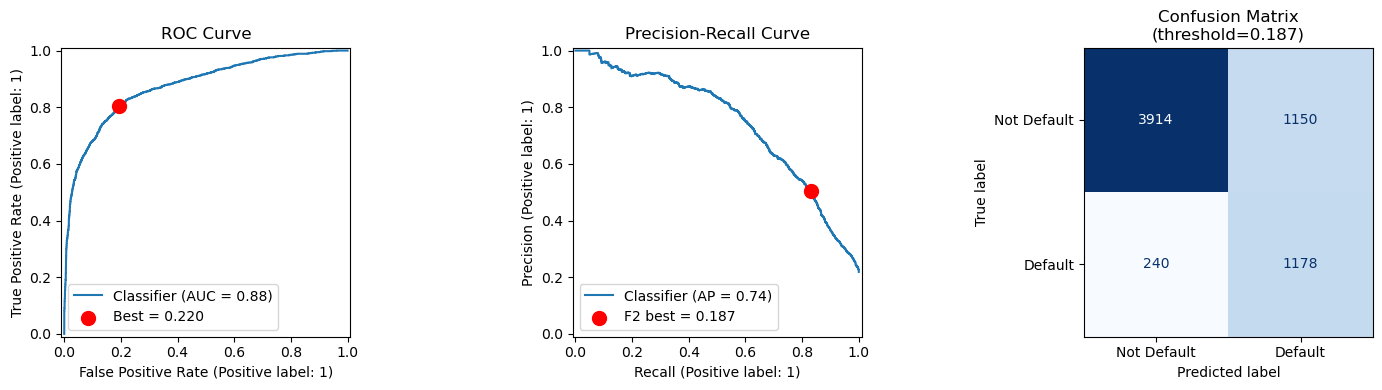

AUC                      : 0.8761
Threshold (ROC/Youden J) : 0.220
Threshold (PR/F2)       : 0.187

--- At PR-based threshold (0.187) ---
TP (caught defaulters)   : 1178
FN (missed defaulters)   : 240
FP (wrongly rejected)    : 1150
TN (correctly approved)  : 3914


In [88]:
results = find_threshold_and_plot(y_test, y_prob, beta=2)

# Access the chosen threshold for use elsewhere in your pipeline
FINAL_THRESHOLD = results['threshold_pr']

In [89]:
import os
import pickle
import numpy as np

# Ensure artifacts directory exists — same pattern as SMS project
os.makedirs("../03_models", exist_ok=True)


# app logic

In [2]:

# logic of the app full workflow

# 1. import the dataset
df = pd.read_csv("../01_data/credit_risk_clean.csv")
numeric_columns = [
    "age", "annual_income", "employment_years", "loan_amount",
    "interest_rate", "loan_income_ratio", "credit_history_years",
]
categorical_columns = [
    "home_ownership", "loan_purpose", "credit_grade", "prior_default_flag",
]
all_raw_columns = numeric_columns + categorical_columns
X = df[all_raw_columns]
y = df['default_flag']

# 2. train test split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 3. fill missing values
missing_cols = X_train[numeric_columns].columns[X_train[numeric_columns].isna().any()].tolist()
missing_indicator = AddMissingIndicator(variables=missing_cols)
median_imputer = MeanMedianImputer(imputation_method='median',variables=missing_cols)

X_train = missing_indicator.fit_transform(X_train)
X_test = missing_indicator.transform(X_test)

X_train = median_imputer.fit_transform(X_train)
X_test = median_imputer.transform(X_test)


indicator_cols = [c for c in X_train.columns if c.endswith('_na')]
X_train.drop(columns=indicator_cols,inplace=True)
X_test.drop(columns=indicator_cols,inplace=True)

# 4. Quantile bining
quantile_binner = EqualFrequencyDiscretiser(
    q=10, 
    variables=numeric_columns, 
    return_object=True
)
X_train = quantile_binner.fit_transform(X_train)
X_test = quantile_binner.transform(X_test)
all_encode_columns = numeric_columns + categorical_columns

for col in all_encode_columns:
    X_train[col] = X_train[col].astype('category')
    X_test[col] = X_test[col].astype('category')

# 5. woe weight of evidence 
woe_encoder = WoEEncoder(variables=all_encode_columns)
X_train_woe = woe_encoder.fit_transform(X_train, y_train)
X_test_woe = woe_encoder.transform(X_test)

# 6. logistic regresion model

logistic_regression_model = LogisticRegression()
logistic_regression_model.fit(X_train_woe,y_train)

print(logistic_regression_model.intercept_)
print(logistic_regression_model.coef_)

# 7. Evaualte get probabilites on test set
test_proba = logistic_regression_model.predict_proba(X_test_woe[all_encode_columns])[:, 1]

auc = roc_auc_score(y_test, test_proba)
print(f"\nTest AUC: {auc:.4f}")


# 8. threshold selction
precisions, recalls, pr_thresholds = precision_recall_curve(y_test, test_proba)

beta = 2
f_scores = (1 + beta**2) * (precisions * recalls) / (beta**2 * precisions + recalls + 1e-10)
best_pr_idx = np.argmax(f_scores[:-1])
FINAL_THRESHOLD = pr_thresholds[best_pr_idx]

print(f"Selected threshold (F2-optimal): {FINAL_THRESHOLD:.4f}")

# Approve threshold — review-band lower bound (half the gap to 0, as discussed)
approve_cutoff = FINAL_THRESHOLD / 2
print(f"Approve threshold: {approve_cutoff:.4f}")

[-1.35394487]
[[ 0.21491637  0.80946115  0.28266075  0.37557427  0.08365528  0.96265034
   0.17571019  0.92451808  1.43107385  1.14279571 -0.0497877 ]]

Test AUC: 0.8761
Selected threshold (F2-optimal): 0.1866
Approve threshold: 0.0933


In [15]:
# pickle all files 
import pickle 

with open("../03_models/median_imputer.pkl", "wb") as f:
    pickle.dump(median_imputer, f)

with open("../03_models/binner.pkl", "wb") as f:
    pickle.dump(quantile_binner, f)

with open("../03_models/woe_encoder.pkl", "wb") as f:
    pickle.dump(woe_encoder, f)

# ---- Fitted model ----
with open("../03_models/logreg_model.pkl", "wb") as f:
    pickle.dump(logistic_regression_model, f)

# ---- Config / reference values ----
config = {
    'numeric_columns': numeric_columns,
    'categorical_columns': categorical_columns,
    'all_encode_columns': all_encode_columns,
    'reject_threshold': FINAL_THRESHOLD,
    'approve_threshold': approve_cutoff,
    'score_offset': 600,
    'score_factor': 20 / np.log(2),
    'grade_rate_map': {
        'A': 6.5, 'B': 8.5, 'C': 10.5, 'D': 13.5,
        'E': 16.5, 'F': 19.0, 'G': 21.5
    },
    'dropdown_options': {
        'home_ownership': sorted(df['home_ownership'].unique().tolist()),
        'loan_purpose': sorted(df['loan_purpose'].unique().tolist()),
        'credit_grade': sorted(df['credit_grade'].unique().tolist()),
        'prior_default_flag': sorted(df['prior_default_flag'].unique().tolist()),
    },
}

with open("../03_models/config.pkl", "wb") as f:
    pickle.dump(config, f)

print(
    "\nSuccessfully exported: median_imputer.pkl, binner.pkl, "
    "woe_encoder.pkl, logreg_model.pkl, config.pkl"
)


Successfully exported: median_imputer.pkl, binner.pkl, woe_encoder.pkl, logreg_model.pkl, config.pkl


In [5]:
# compute everything once and display in streamlit 

test_proba = logistic_regression_model.predict_proba(X_test_woe[all_encode_columns])[:, 1]

# ROC
fpr, tpr, _ = roc_curve(y_test, test_proba)
auc = roc_auc_score(y_test, test_proba)
gini = 2 * auc - 1

# Precision-Recall
precisions, recalls, _ = precision_recall_curve(y_test, test_proba)
avg_precision = average_precision_score(y_test, test_proba)

# KS
def calculate_ks(y_true, y_proba):
    df_ks = pd.DataFrame({'y_true': y_true, 'proba': y_proba}).sort_values('proba', ascending=False)
    df_ks['cum_bad'] = (df_ks['y_true'] == 1).cumsum() / (df_ks['y_true'] == 1).sum()
    df_ks['cum_good'] = (df_ks['y_true'] == 0).cumsum() / (df_ks['y_true'] == 0).sum()
    df_ks['population_pct'] = np.arange(1, len(df_ks) + 1) / len(df_ks)
    df_ks['ks'] = np.abs(df_ks['cum_bad'] - df_ks['cum_good'])
    return df_ks['ks'].max(), df_ks

ks_stat, ks_df = calculate_ks(y_test, test_proba)

# Confusion matrix at your chosen threshold
y_pred_final = (test_proba >= FINAL_THRESHOLD).astype(int)
cm = confusion_matrix(y_test, y_pred_final)

# Calibration
prob_true, prob_pred = calibration_curve(y_test, test_proba, n_bins=10)

# IV table (reuse your calculate_iv function)
iv_results = {col: calculate_iv(X_train[col], y_train) for col in all_encode_columns}
iv_table = pd.DataFrame(
    sorted(iv_results.items(), key=lambda x: x[1], reverse=True),
    columns=['Variable', 'IV']
)

# Bundle everything into one dict and pickle

evaluation_metrics = {
    'auc': auc,
    'gini': gini,
    'ks_stat': ks_stat,
    'avg_precision': avg_precision,
    'threshold': FINAL_THRESHOLD,
    'fpr': fpr, 'tpr': tpr,
    'precisions': precisions, 'recalls': recalls,
    'ks_df': ks_df[['population_pct', 'cum_bad', 'cum_good']],
    'confusion_matrix': cm,
    'prob_true': prob_true, 'prob_pred': prob_pred,
    'iv_table': iv_table,
}


In [ ]:
evaluation_metrics

{'auc': 0.8761352571429845,
 'gini': 0.7522705142859689,
 'ks_stat': 0.6116111515896943,
 'avg_precision': 0.7436029206732877,
 'threshold': 0.18663241858845597,
 'fpr': array([0.        , 0.        , 0.        , ..., 0.96149289, 0.96149289,
        1.        ]),
 'tpr': array([0.00000000e+00, 7.05218618e-04, 4.93653032e-02, ...,
        9.99294781e-01, 1.00000000e+00, 1.00000000e+00]),
 'precisions': array([0.21875964, 0.2187934 , 0.21882716, ..., 1.        , 1.        ,
        1.        ]),
 'recalls': array([1.00000000e+00, 1.00000000e+00, 1.00000000e+00, ...,
        1.41043724e-03, 7.05218618e-04, 0.00000000e+00]),
 'ks_df':        population_pct   cum_bad  cum_good
 10147        0.000154  0.000705  0.000000
 12214        0.000309  0.001410  0.000000
 16375        0.000463  0.002116  0.000000
 26610        0.000617  0.002821  0.000000
 5288         0.000771  0.003526  0.000000
 ...               ...       ...       ...
 15197        0.999383  1.000000  0.999210
 26966        0.99

In [9]:
import pickle
with open("../03_models/evaluation_metrics.pkl", "wb") as f:
    pickle.dump(evaluation_metrics, f)

print("Saved evaluation_metrics.pkl")

Saved evaluation_metrics.pkl
